In [9]:
# 数据处理库
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# PyTorch库
import torch
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
from torchvision import models, datasets


import warnings
warnings.filterwarnings('ignore')

# 设置随机种子，保证结果可重复
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(42)

# 设备配置
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [10]:
import cv2

# 导出数据集
base_directory = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset'
train_folder = 'Training'  
test_folder = 'Testing'    

# 获取所有类别名称
train_path = os.path.join(base_directory, train_folder)
categories = os.listdir(train_path)
print(categories)
print(train_path)

['pituitary', 'notumor', 'meningioma', 'glioma']
/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training


['pituitary', 'notumor', 'meningioma', 'glioma']
Data Exploration

Training Set Distribution:


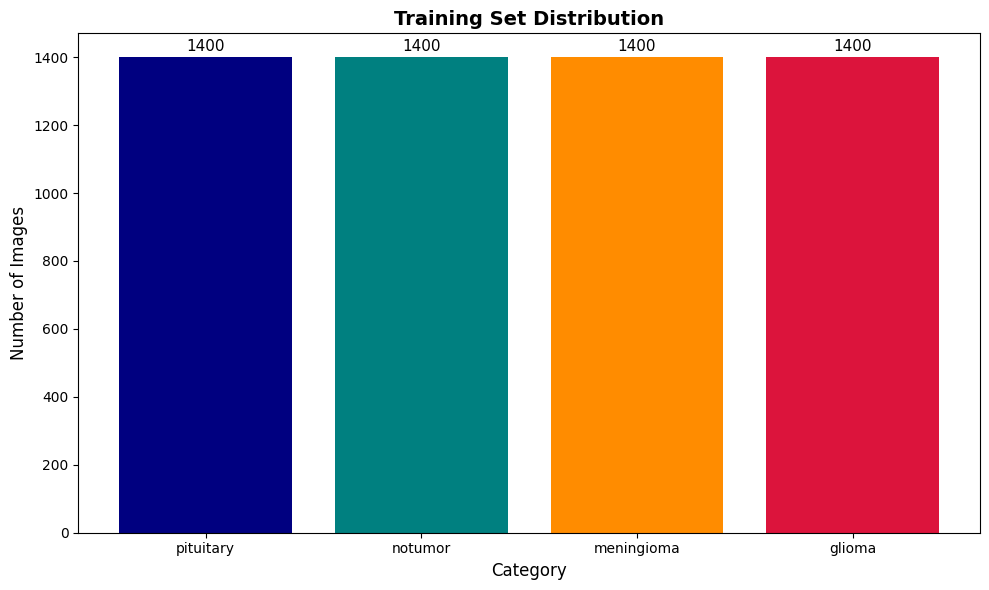


Test Set Distribution:


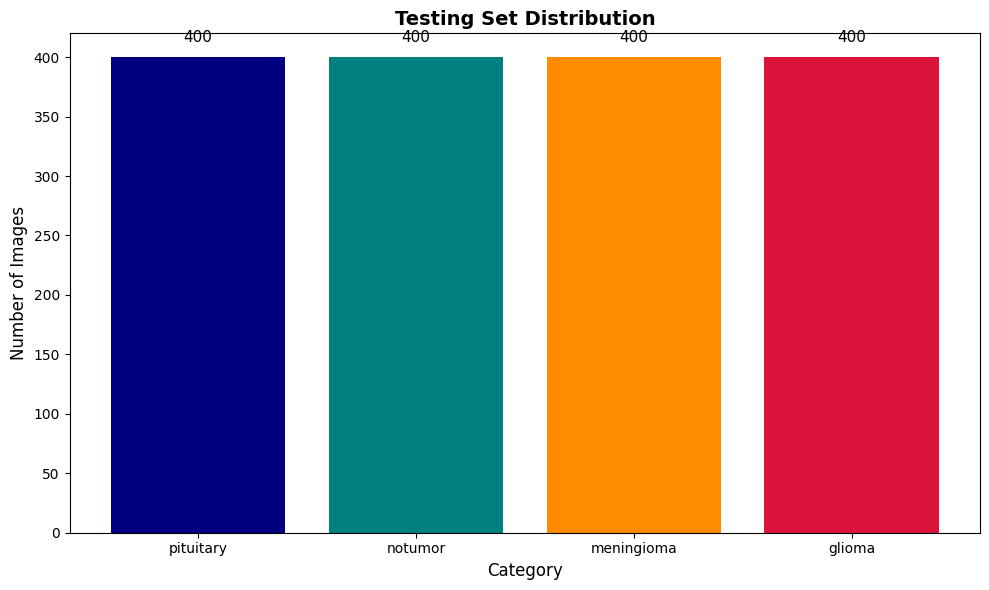


Training Set Samples:


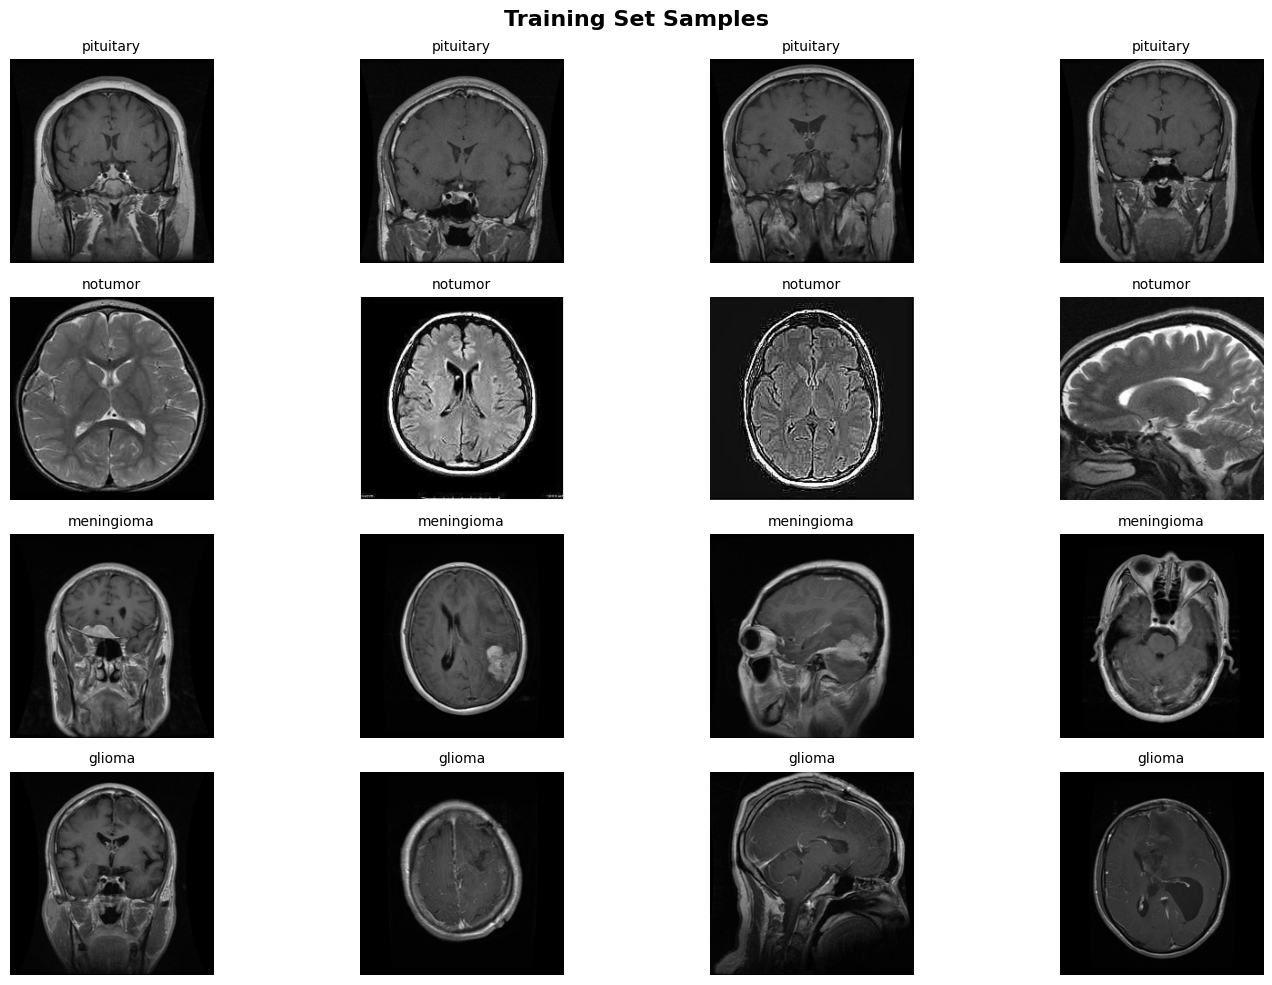


Test Set Samples:


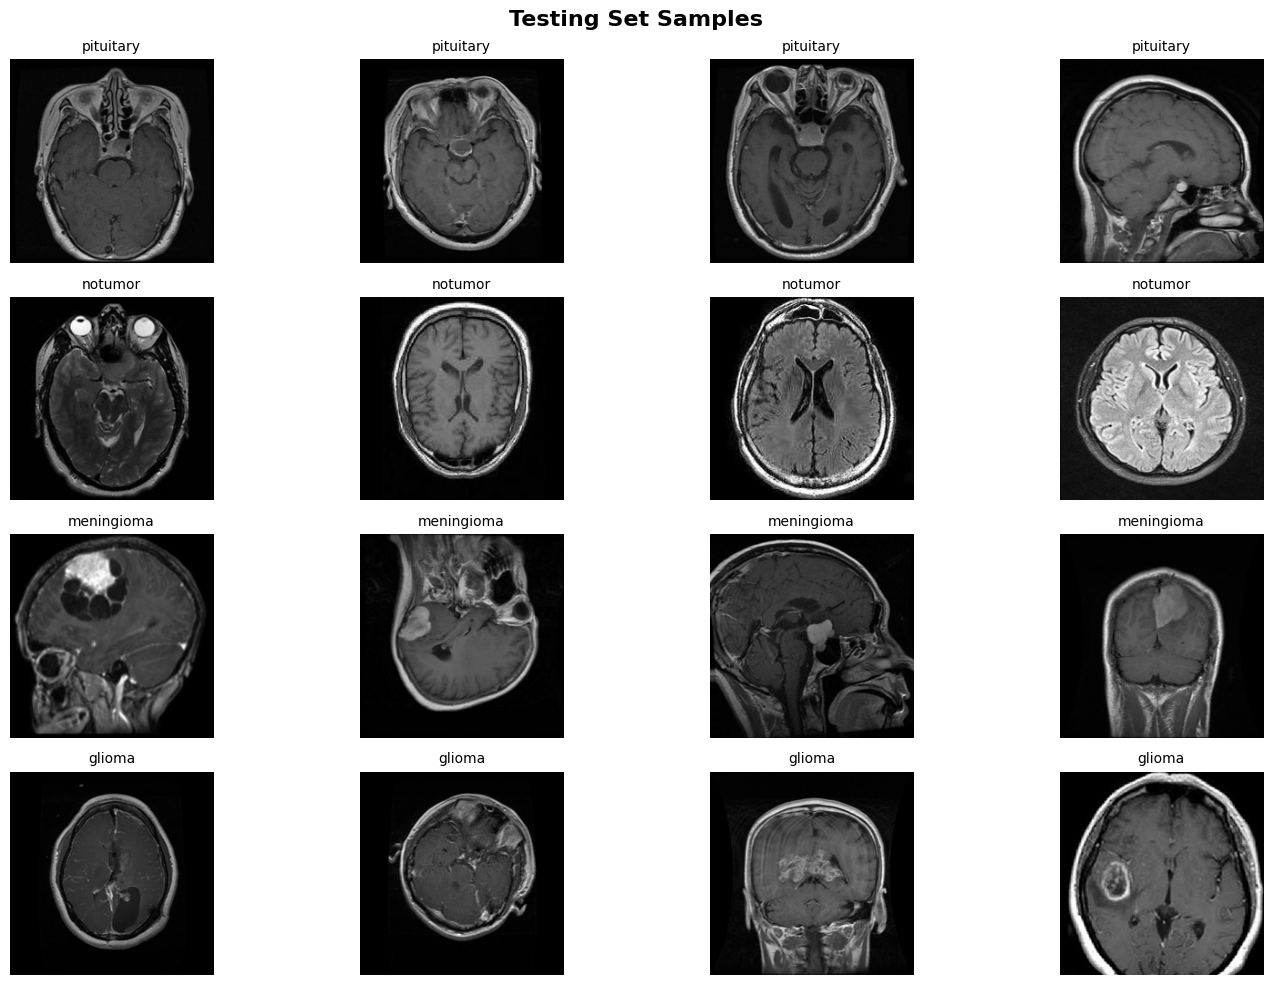

In [11]:
# 设置路径和参数
# 设置路径
base_directory = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset'
train_folder = 'Training'
test_folder = 'Testing'

# 获取类别
train_path = os.path.join(base_directory, train_folder)
categories = [cat for cat in os.listdir(train_path) if not cat.startswith('.')]
print(categories)

# 数据探索函数

def plot_class_distribution(dataset_type):
    path = os.path.join(base_directory, dataset_type)
    counts = [len(os.listdir(os.path.join(path, cat))) for cat in categories]
    
    plt.figure(figsize=(10, 6))
    bars = plt.bar(categories, counts, color=['navy', 'teal', 'darkorange', 'crimson'])
    plt.xlabel("Category", fontsize=12)
    plt.ylabel("Number of Images", fontsize=12)
    plt.title(f"{dataset_type} Set Distribution", fontsize=14, fontweight='bold')
    
    # 在柱状图上添加数值标签
    for bar, count in zip(bars, counts):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                str(count), ha='center', va='bottom', fontsize=11)
    
    plt.tight_layout()
    plt.show()


def display_images(dataset_type, num_images=4, image_size=(224, 224)):
    dataset_path = os.path.join(base_directory, dataset_type)
    
    fig, axes = plt.subplots(len(categories), num_images, figsize=(15, 10))
    # 处理只有一行的情况
    if len(categories) == 1:
        axes = axes.reshape(1, -1)
    
    for row, category in enumerate(categories):
        category_path = os.path.join(dataset_path, category)
        # 过滤掉系统文件
        image_files = [f for f in os.listdir(category_path) if not f.startswith('.')]
        
    # 随机选取图片
        if len(image_files) >= num_images:
            image_filenames = random.sample(image_files, num_images)
        else:
            image_filenames = image_files
    # 如果图片不足，重复最后一张
            while len(image_filenames) < num_images:
                image_filenames.append(image_filenames[-1])
        
        for col, image_filename in enumerate(image_filenames[:num_images]):
            image_path = os.path.join(category_path, image_filename)
            try:
                image = Image.open(image_path).resize(image_size)
                axes[row, col].imshow(image, cmap='gray')
            except Exception as e:
                print(f"Cannot load image: {e}")
                axes[row, col].text(0.5, 0.5, 'Load failed', ha='center', va='center')
            axes[row, col].axis('off')
            axes[row, col].set_title(f"{category}", fontsize=10)
    
    plt.suptitle(f"{dataset_type} Set Samples", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# 执行数据探索
print("Data Exploration")
# 绘制训练集和测试集的类别分布
print("\nTraining Set Distribution:")
plot_class_distribution(train_folder)

print("\nTest Set Distribution:")
plot_class_distribution(test_folder)

# 展示训练集和测试集的样本图片
print("\nTraining Set Samples:")
display_images(train_folder, num_images=4)

print("\nTest Set Samples:")
display_images(test_folder, num_images=4)

In [12]:
from torch.utils.data import random_split
# 设置参数
target_size = (224, 224)  # 图像大小
batch_size = 32  # 批次大小
num_workers = 2  # 数据加载进程数

# 设置设备
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 自定义数据集类
label_map = {category: idx for idx, category in enumerate(categories)}
class BrainTumorDataset(Dataset):
    def __init__(self, data_dir, transform=None):
        self.data_dir = data_dir
        self.transform = transform
        self.images = []
        self.labels = []
        
        # 遍历每个类别文件夹
        for category in categories:
            category_path = os.path.join(data_dir, category)
       # 获取该类别的所有图片文件名
            for img_name in os.listdir(category_path):
                if img_name.endswith('.jpg'):
                    self.images.append(os.path.join(category_path, img_name))
                    self.labels.append(label_map[category])
        
        print(f"Loaded: {len(self.images)} images from {data_dir}")
    
    def __len__(self):
        return len(self.images)
    
    def __getitem__(self, idx):
        # 读取图片并转换为RGB格式
        image = Image.open(self.images[idx]).convert('RGB')
        label = self.labels[idx]
        
        # 应用图像变换
        if self.transform:
            image = self.transform(image)
        
        return image, label


# 图像预处理与数据增强
# 训练集的数据增强和归一化
train_transforms = transforms.Compose([
    transforms.Resize(target_size),                    # 调整大小
    transforms.RandomHorizontalFlip(p=0.5),            # 随机水平翻转
    transforms.ToTensor(),                              # 转换为张量
    transforms.Normalize(                               # 归一化
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 验证集和测试集：调整大小和归一化
val_transforms = transforms.Compose([
    transforms.Resize(target_size),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transforms = transforms.Compose([
    transforms.Resize(target_size),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# 创建训练集
print("\nCreating Datasets")

full_train_dataset = BrainTumorDataset(
    os.path.join(base_directory, train_folder),
    transform=train_transforms
)

# 创建测试集
test_dataset = BrainTumorDataset(
    os.path.join(base_directory, test_folder),
    transform=test_transforms
)


# 设置验证集比例并划分（占比30%）
val_ratio = 0.30
val_size = int(len(full_train_dataset) * val_ratio)
train_size = len(full_train_dataset) - val_size

print("Dataset Split")
print(f"Full training set size: {len(full_train_dataset)}")
print(f"New training set size: {train_size} ({100*(1-val_ratio):.0f}%)")
print(f"Validation set size: {val_size} ({val_ratio*100:.0f}%)")
print(f"Test set size: {len(test_dataset)}")

# 随机划分训练集和验证集（固定随机种子，保证可重复性）
train_dataset, val_dataset = random_split(
    full_train_dataset, 
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

val_dataset.dataset.transform = val_transforms

# 创建数据加载器
print("\nCreating DataLoaders")

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# 创建生成器
g = torch.Generator()
g.manual_seed(42)

# 训练数据加载器
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    worker_init_fn=seed_worker,
    generator=g,
    pin_memory=True if torch.cuda.is_available() else False
)

# 验证数据加载器
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True if torch.cuda.is_available() else False
)

# 测试数据加载器
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")
# 验证每个类别的分布
# 计算训练集中各类别数量
train_class_counts = {}
for idx in range(len(train_dataset)):
    _, label = train_dataset[idx]
    class_name = categories[label]
    train_class_counts[class_name] = train_class_counts.get(class_name, 0) + 1

for class_name in categories:
    count = train_class_counts.get(class_name, 0)
    print(f"  {class_name}: {count} images ({count/len(train_dataset)*100:.1f}%)")
# 计算验证集中各类别数量
val_class_counts = {}
for idx in range(len(val_dataset)):
    _, label = val_dataset[idx]
    class_name = categories[label]
    val_class_counts[class_name] = val_class_counts.get(class_name, 0) + 1
for class_name in categories:
    count = val_class_counts.get(class_name, 0)
    print(f"  {class_name}: {count} images ({count/len(val_dataset)*100:.1f}%)")
# 计算测试集中各类别数量
test_class_counts = {}
for idx in range(len(test_dataset)):
    _, label = test_dataset[idx]
    class_name = categories[label]
    test_class_counts[class_name] = test_class_counts.get(class_name, 0) + 1

for class_name in categories:
    count = test_class_counts.get(class_name, 0)
    print(f"  {class_name}: {count} images ({count/len(test_dataset)*100:.1f}%)")
print("Data preparation complete")


Creating Datasets
Loaded: 5600 images from /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Loaded: 1600 images from /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
Dataset Split
Full training set size: 5600
New training set size: 3920 (70%)
Validation set size: 1680 (30%)
Test set size: 1600

Creating DataLoaders
Training batches: 123
Validation batches: 53
Test batches: 50
  pituitary: 989 images (25.2%)
  notumor: 973 images (24.8%)
  meningioma: 977 images (24.9%)
  glioma: 981 images (25.0%)
  pituitary: 411 images (24.5%)
  notumor: 427 images (25.4%)
  meningioma: 423 images (25.2%)
  glioma: 419 images (24.9%)
  pituitary: 400 images (25.0%)
  notumor: 400 images (25.0%)
  meningioma: 400 images (25.0%)
  glioma: 400 images (25.0%)
Data preparation complete


In [16]:
# 初始化模型

print("Model Building")

num_classes = len(categories)
print(f"Number of classes: {num_classes}")
print(f"Classes: {categories}")

# 创建模型
def create_model(num_classes=4):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)  # 预训练
    
    for param in model.parameters():
        param.requires_grad = False
    
    for param in model.layer4.parameters():
        param.requires_grad = True
    
    num_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(0.6),           
        nn.Linear(num_features, 128), 
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),          
        nn.Linear(128, num_classes)
    )
    
    return model

model = create_model(num_classes=num_classes)
model = model.to(device)

# 优化器配置
criterion = nn.CrossEntropyLoss()
learning_rate = 0.0001      
weight_decay = 0.05         

optimizer = optim.Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)

# 学习率调度器
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-7
)  

# 统计参数
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Trainable ratio: {trainable_params/total_params*100:.1f}%")
print(f"Model loaded to: {device}")

Model Building
Number of classes: 4
Classes: ['pituitary', 'notumor', 'meningioma', 'glioma']
Total parameters: 23,770,820
Trainable parameters: 15,227,524
Trainable ratio: 64.1%
Model loaded to: cuda


In [17]:
# 模型训练

from tqdm import tqdm
import torch
import torch.nn as nn
import torch.optim as optim

# 训练一个epoch的函数

def train_epoch(model, train_loader, criterion, optimizer, device):

    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    pbar = tqdm(train_loader, desc='Training', unit='batch')
    for inputs, labels in pbar:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        current_acc = 100. * correct / total
        pbar.set_postfix({'loss': f'{loss.item():.3f}', 'acc': f'{current_acc:.1f}%'})
    
    epoch_loss = running_loss / len(train_loader)
    epoch_acc = 100. * correct / total
    
    return epoch_loss, epoch_acc

# 验证函数

def validate(model, val_loader, criterion, device):
  
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    
    val_loss = running_loss / len(val_loader)
    val_acc = 100. * correct / total
    
    return val_loss, val_acc

#训练

def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, 
                num_epochs, device, save_path='best_model.pth', patience=5):

    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }
    best_val_acc = 0
    counter = 0
    
    print("Starting Training")
    
    for epoch in range(num_epochs):
        print(f"\nEpoch [{epoch+1}/{num_epochs}]")
       
        
        # 训练
        train_loss, train_acc = train_epoch(
            model, train_loader, criterion, optimizer, device
        )
        
        # 验证
        val_loss, val_acc = validate(
            model, val_loader, criterion, device
        )
        
        # 更新学习率
        old_lr = optimizer.param_groups[0]['lr']
        scheduler.step(val_loss)
        new_lr = optimizer.param_groups[0]['lr']
        
        # 记录历史
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        
        
        # 打印结果
        print(f"Train - Loss: {train_loss:.6f}, Acc: {train_acc:.4f}%")
        print(f"Val   - Loss: {val_loss:.6f}, Acc: {val_acc:.4f}%")
        if new_lr < old_lr:
            print(f" (reduced from {old_lr:.6f})")
        else:
            print()
        
        # 保存最佳模型和早停判断
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            counter = 0
            print(f" Best model  (Acc: {best_val_acc:.1f}%)")
  
    
    print(f"Training Completed!")
    print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
    
    return history


# 设置训练参数
num_epochs = 10
patience = 5

# 开始训练
history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    scheduler=scheduler,
    num_epochs=num_epochs,
    device=device,
    save_path='best_model.pth',
    patience=patience
)


Starting Training

Epoch [1/10]


Training: 100%|██████████| 123/123 [00:20<00:00,  6.14batch/s, loss=0.330, acc=81.9%]


Train - Loss: 0.524989, Acc: 81.8878%
Val   - Loss: 0.248002, Acc: 91.6071%

 Best model  (Acc: 91.6%)

Epoch [2/10]


Training: 100%|██████████| 123/123 [00:20<00:00,  5.87batch/s, loss=0.712, acc=94.7%]


Train - Loss: 0.179232, Acc: 94.6939%
Val   - Loss: 0.170115, Acc: 94.1667%

 Best model  (Acc: 94.2%)

Epoch [3/10]


...

Train - Loss: 0.036155, Acc: 99.4643%
Val   - Loss: 0.083435, Acc: 97.6190%

 Best model  (Acc: 97.6%)

Epoch [9/10]


Training: 100%|██████████| 123/123 [00:20<00:00,  6.09batch/s, loss=0.054, acc=98.9%]


Train - Loss: 0.053824, Acc: 98.8520%
Val   - Loss: 0.096818, Acc: 97.2619%
 (reduced from 0.000050)

Epoch [10/10]


Training: 100%|██████████| 123/123 [00:20<00:00,  6.10batch/s, loss=0.021, acc=99.4%]


Train - Loss: 0.030726, Acc: 99.4388%
Val   - Loss: 0.072554, Acc: 97.8571%

 Best model  (Acc: 97.9%)
Training Completed!
Best Validation Accuracy: 97.86%



Training: Full_Model


Epoch 1/10: 100%|██████████| 123/123 [00:16<00:00,  7.31it/s, loss=0.122, acc=81.8%]


Epoch 1: Train Acc=81.84%, Val Acc=95.06%


Epoch 2/10: 100%|██████████| 123/123 [00:17<00:00,  7.14it/s, loss=0.225, acc=94.1%]


Epoch 2: Train Acc=94.13%, Val Acc=91.37%


...

Epoch 8: Train Acc=82.19%, Val Acc=87.02%


Epoch 9/10: 100%|██████████| 123/123 [00:13<00:00,  8.94it/s, loss=0.437, acc=82.6%]


Epoch 9: Train Acc=82.60%, Val Acc=87.80%


Epoch 10/10: 100%|██████████| 123/123 [00:13<00:00,  8.86it/s, loss=0.635, acc=82.1%]


Epoch 10: Train Acc=82.14%, Val Acc=87.50%
No_Fine_tune - Best Val Acc: 87.80%
Ablation Study Results
       Model  Best Val Acc (%)
  Full_Model             97.56
  No_Dropout             96.37
No_Fine_tune             87.80


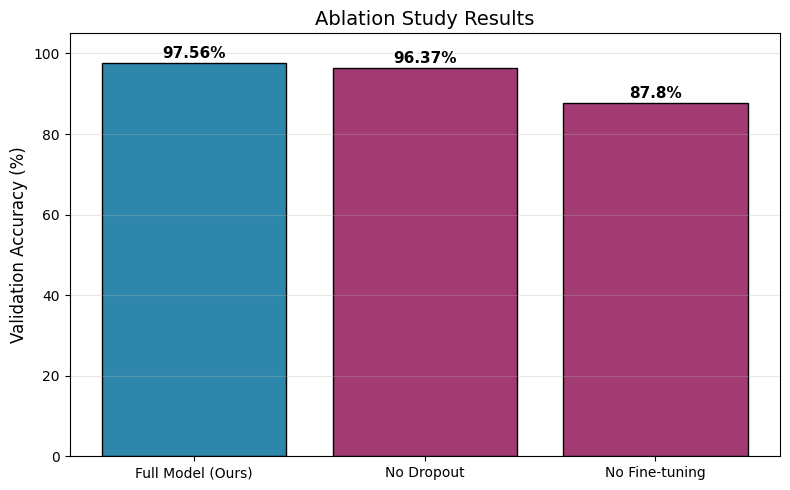

In [22]:
import torch.nn as nn
import torch.optim as optim
from torchvision import models
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm

#  定义3个消融模型变体
#完整模型
def create_ablation_model_full(num_classes=4):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    
    for param in model.parameters():
        param.requires_grad = False
    for param in model.layer4.parameters():
        param.requires_grad = True
    
    num_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(0.6),
        nn.Linear(num_features, 128),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(128, num_classes)
    )
    return model

#1：无Dropout
def create_ablation_model_no_dropout(num_classes=4):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    
    for param in model.parameters():
        param.requires_grad = False
    for param in model.layer4.parameters():
        param.requires_grad = True
    
    num_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Linear(num_features, 128),
        nn.ReLU(inplace=True),
        nn.Linear(128, num_classes)
    )
    return model

#2：无微调（完全冻结，只训练分类头
def create_ablation_model_no_finetune(num_classes=4):
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    
    # 完全冻结所有卷积层
    for param in model.parameters():
        param.requires_grad = False
    
    num_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(0.6),
        nn.Linear(num_features, 128),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(128, num_classes)
    )
    return model


# 消融实验训练函数 

def train_ablation_model(model, train_loader, val_loader, device, num_epochs=10, model_name="Model"):
    
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001, weight_decay=0.05)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
    
    best_val_acc = 0
    patience_counter = 0
    
    print(f"Training: {model_name}")
    
    for epoch in range(num_epochs):
        # 训练
        model.train()
        train_correct = 0
        train_total = 0
        train_loss = 0.0
        
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")
        for inputs, labels in pbar:
            inputs, labels = inputs.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            _, predicted = outputs.max(1)
            train_total += labels.size(0)
            train_correct += predicted.eq(labels).sum().item()
            pbar.set_postfix({'loss': f'{loss.item():.3f}', 'acc': f'{100.*train_correct/train_total:.1f}%'})
        
        train_acc = 100. * train_correct / train_total
        train_loss = train_loss / len(train_loader)
        
        # 验证
        model.eval()
        val_correct = 0
        val_total = 0
        val_loss = 0.0
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                
                val_loss += loss.item()
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()
        
        val_acc = 100. * val_correct / val_total
        val_loss = val_loss / len(val_loader)
        
        # 学习率调整
        scheduler.step(val_loss)
        
        # 早停判断
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), f"ablation_best_{model_name}.pth")
        else:
            patience_counter += 1
        
        print(f"Epoch {epoch+1}: Train Acc={train_acc:.2f}%, Val Acc={val_acc:.2f}%")
        
        if patience_counter >= 5:
            print(f"Early stopping at epoch {epoch+1}")
            break
    
    print(f"{model_name} - Best Val Acc: {best_val_acc:.2f}%")
    return best_val_acc


#消融实验 

def run_ablation_study(train_loader, val_loader, device):
    models_config = [
        ("Full_Model", create_ablation_model_full),
        ("No_Dropout", create_ablation_model_no_dropout),
        ("No_Fine_tune", create_ablation_model_no_finetune),
    ]
    
    results = []
    
    for model_name, model_creator in models_config:
        model = model_creator()
        best_acc = train_ablation_model(model, train_loader, val_loader, device, 
                                        num_epochs=10, model_name=model_name)
        results.append({
            "Model": model_name,
            "Best Val Acc (%)": round(best_acc, 2)
        })
    
    # 输出结果
    df_results = pd.DataFrame(results)
    df_results = df_results.sort_values("Best Val Acc (%)", ascending=False)
    print("Ablation Study Results")
    print(df_results.to_string(index=False))
    
    df_results.to_csv("ablation_results.csv", index=False)
    
    return df_results


# 绘制结果图 

def plot_ablation_results(results_df):
    plt.figure(figsize=(8, 5))
 
    name_mapping = {
        "Full_Model": "Full Model (Ours)",
        "No_Dropout": "No Dropout",
        "No_Fine_tune": "No Fine-tuning"
    }
    
    models = [name_mapping.get(m, m) for m in results_df["Model"].tolist()]
    accuracies = results_df["Best Val Acc (%)"].tolist()
    
    colors = ['#2E86AB' if m == "Full Model (Ours)" else '#A23B72' for m in models]
    
    bars = plt.bar(models, accuracies, color=colors, edgecolor='black')
    
    for bar, acc in zip(bars, accuracies):
        plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, 
                f'{acc}%', ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    plt.ylabel('Validation Accuracy (%)', fontsize=12)
    plt.title('Ablation Study Results', fontsize=14)
    plt.ylim(0, 105)
    plt.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('ablation_results.png', dpi=300)
    plt.show()

results = run_ablation_study(train_loader, val_loader, device)
plot_ablation_results(results)

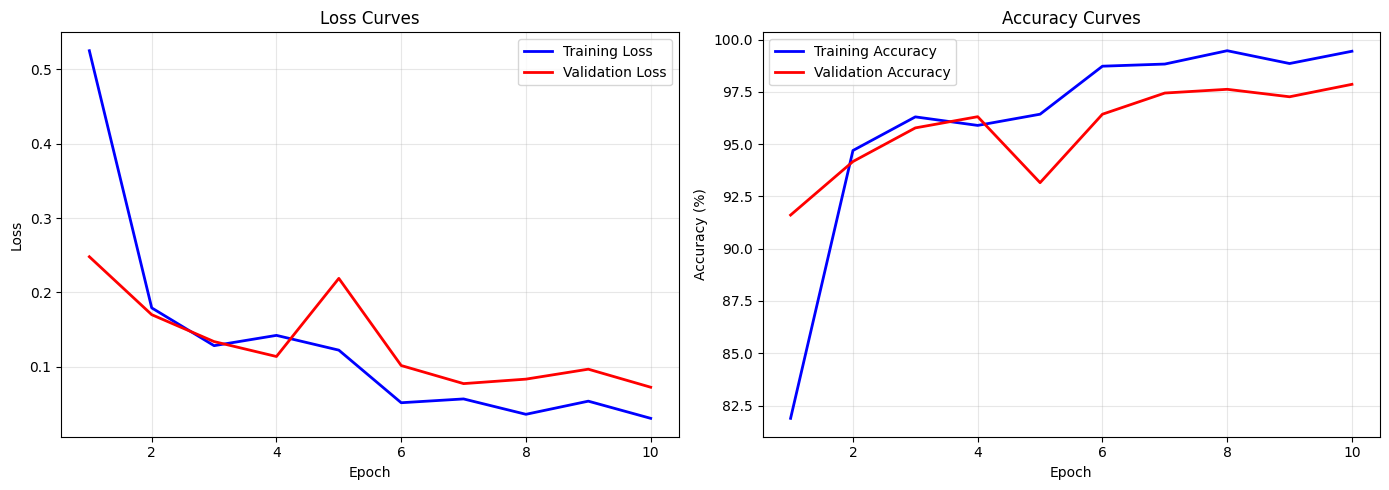

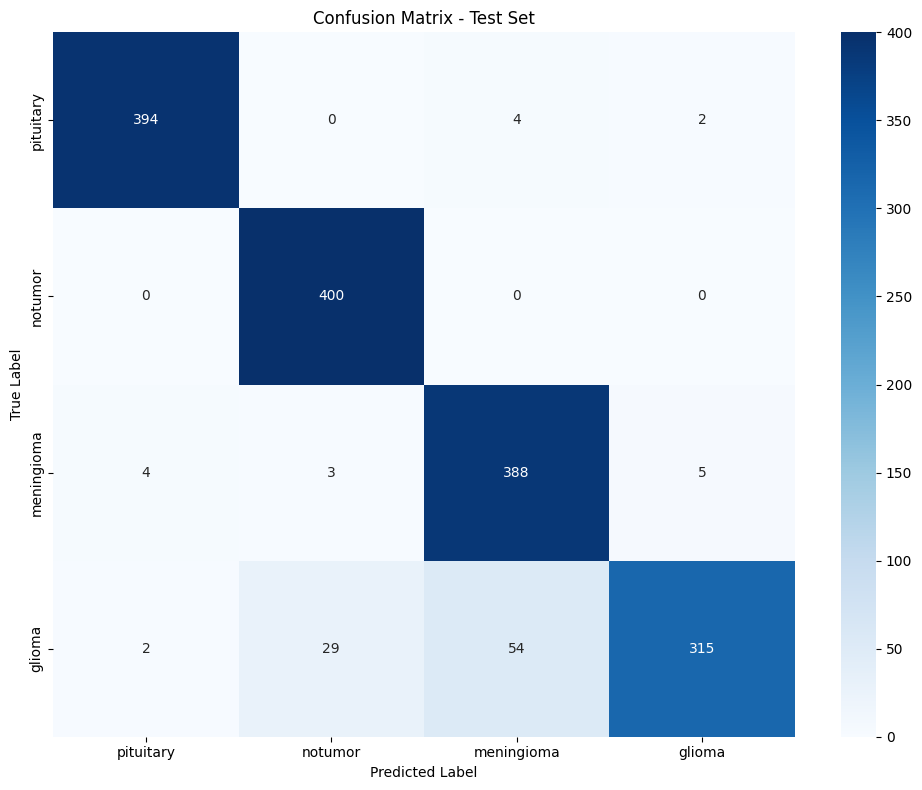

In [18]:
from sklearn.metrics import classification_report, confusion_matrix

# 训练曲线可视化

def plot_training_curves(history):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    epochs = range(1, len(history['train_loss']) + 1)
    
    ax1.plot(epochs, history['train_loss'], 'b-', label='Training Loss', linewidth=2)
    ax1.plot(epochs, history['val_loss'], 'r-', label='Validation Loss', linewidth=2)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title('Loss Curves')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    ax2.plot(epochs, history['train_acc'], 'b-', label='Training Accuracy', linewidth=2)
    ax2.plot(epochs, history['val_acc'], 'r-', label='Validation Accuracy', linewidth=2)
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Accuracy (%)')
    ax2.set_title('Accuracy Curves')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('training_curves.png', dpi=150)
    plt.show()

# 模型测试集评估

def evaluate_best_model(model, test_loader, device):
    best_model_path = 'best_model.pth'
    if os.path.exists(best_model_path):
        model.load_state_dict(torch.load(best_model_path))
    
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    cm = confusion_matrix(all_labels, all_preds)
    
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=categories, yticklabels=categories)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title('Confusion Matrix - Test Set')
    plt.tight_layout()
    plt.savefig('confusion_matrix_test.png', dpi=150)
    plt.show()


if 'history' in globals():
    plot_training_curves(history)

if 'model' in globals() and 'test_loader' in globals():
    evaluate_best_model(model, test_loader, device)

In [20]:
# VGG16 模型构建(参数一样)

print("VGG16")

num_classes = len(categories)

def create_vgg16_model(num_classes=4):
    from torchvision import models
    
    model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
    
    for param in model.parameters():
        param.requires_grad = False
    
    for param in model.classifier[6].parameters():
        param.requires_grad = True
    
    num_features = model.classifier[6].in_features  
    model.classifier[6] = nn.Sequential(
        nn.Dropout(0.6),           
        nn.Linear(num_features, 128), 
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),          
        nn.Linear(128, num_classes)
    )
    
    return model

vgg_model = create_vgg16_model(num_classes=num_classes)
vgg_model = vgg_model.to(device)

criterion = nn.CrossEntropyLoss()
learning_rate = 0.0001      
weight_decay = 0.05         

optimizer = optim.Adam(vgg_model.parameters(), lr=learning_rate, weight_decay=weight_decay)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-7
)

total_params = sum(p.numel() for p in vgg_model.parameters())
trainable_params = sum(p.numel() for p in vgg_model.parameters() if p.requires_grad)
print(device)

VGG16
cuda


In [21]:
num_epochs = 10
patience = 5
best_val_acc = 0
counter = 0

vgg_history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

print("Starting VGG16 Training")

for epoch in range(num_epochs):
    # 训练
    vgg_model.train()
    train_loss = 0
    correct = 0
    total = 0
    
    pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
    for inputs, labels in pbar:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = vgg_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        current_acc = 100. * correct / total
        pbar.set_postfix({'loss': f'{loss.item():.3f}', 'acc': f'{current_acc:.1f}%'})
    
    train_loss /= len(train_loader)
    train_acc = 100. * correct / len(train_loader.dataset)
    
    # 验证
    vgg_model.eval()
    val_loss = 0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = vgg_model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100. * correct / total
    
    # 更新学习率
    old_lr = optimizer.param_groups[0]['lr']
    scheduler.step(val_acc)
    new_lr = optimizer.param_groups[0]['lr']
    
    # 记录历史
    vgg_history['train_loss'].append(train_loss)
    vgg_history['train_acc'].append(train_acc)
    vgg_history['val_loss'].append(val_loss)
    vgg_history['val_acc'].append(val_acc)
    
    # 打印结果
    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Train - Loss: {train_loss:.6f}, Acc: {train_acc:.4f}%")
    print(f"Val   - Loss: {val_loss:.6f}, Acc: {val_acc:.4f}%")
    if new_lr < old_lr:
        print(f" (reduced from {old_lr:.6f})")
    else:
        print()
    
    # 保存最佳模型
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(vgg_model.state_dict(), 'best_vgg16_model.pth')
        counter = 0
        print(f" Best model saved (Acc: {best_val_acc:.1f}%)")

print(f"VGG16 Training Completed")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")

Starting VGG16 Training


Epoch 1/10: 100%|██████████| 123/123 [00:24<00:00,  5.06it/s, loss=1.011, acc=51.9%]



Epoch [1/10]
Train - Loss: 1.102290, Acc: 51.8622%
Val   - Loss: 0.744861, Acc: 75.1786%

 Best model saved (Acc: 75.2%)


Epoch 2/10: 100%|██████████| 123/123 [00:22<00:00,  5.43it/s, loss=0.613, acc=69.5%]



Epoch [2/10]
Train - Loss: 0.770911, Acc: 69.5408%
Val   - Loss: 0.576782, Acc: 79.8214%

 Best model saved (Acc: 79.8%)


...


Epoch [8/10]
Train - Loss: 0.567144, Acc: 78.2908%
Val   - Loss: 0.443831, Acc: 84.1667%

 Best model saved (Acc: 84.2%)


Epoch 9/10: 100%|██████████| 123/123 [00:22<00:00,  5.42it/s, loss=0.782, acc=79.0%]



Epoch [9/10]
Train - Loss: 0.541324, Acc: 78.9541%
Val   - Loss: 0.432309, Acc: 84.5833%

 Best model saved (Acc: 84.6%)


Epoch 10/10: 100%|██████████| 123/123 [00:22<00:00,  5.43it/s, loss=0.365, acc=78.2%]



Epoch [10/10]
Train - Loss: 0.553562, Acc: 78.2143%
Val   - Loss: 0.435987, Acc: 84.4048%

VGG16 Training Completed
Best Validation Accuracy: 84.58%


In [22]:
# VGG16 测试集评估
from sklearn.metrics import classification_report

def evaluate_vgg16_model(model, test_loader, device):
    
    # 加载最佳模型
    best_model_path = 'best_vgg16_model.pth'
    if os.path.exists(best_model_path):
        model.load_state_dict(torch.load(best_model_path))
        print(f"Loaded best VGG16 model from {best_model_path}")
    
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    # 计算准确率
    accuracy = 100. * np.sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)
    
    # 打印结果
    print("VGG16 Test Set Results")
    print(f"Test Accuracy: {accuracy:.2f}%")
    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds, target_names=categories))
    
    return accuracy

# 运行评估
vgg_test_acc = evaluate_vgg16_model(vgg_model, test_loader, device)

Loaded best VGG16 model from best_vgg16_model.pth
VGG16 Test Set Results
Test Accuracy: 78.81%

Classification Report:
              precision    recall  f1-score   support

   pituitary       0.83      0.95      0.89       400
     notumor       0.78      0.98      0.87       400
  meningioma       0.72      0.55      0.62       400
      glioma       0.79      0.68      0.73       400

    accuracy                           0.79      1600
   macro avg       0.78      0.79      0.78      1600
weighted avg       0.78      0.79      0.78      1600



In [24]:
# EfficientNet-B0 模型构建(参数一样)

print("EfficientNet-B0 Model Building")

num_classes = len(categories)

def create_efficientnet_model(num_classes=4):
    from torchvision import models
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False
    
    num_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.6),
        nn.Linear(num_features, 128),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(128, num_classes)
    )
    
    return model


eff_model = create_efficientnet_model(num_classes=num_classes)
eff_model = eff_model.to(device)


criterion = nn.CrossEntropyLoss()
learning_rate = 0.0001
weight_decay = 0.05

optimizer = optim.Adam(eff_model.parameters(), lr=learning_rate, weight_decay=weight_decay)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=3, min_lr=1e-7
)


total_params = sum(p.numel() for p in eff_model.parameters())
trainable_params = sum(p.numel() for p in eff_model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Trainable ratio: {trainable_params/total_params*100:.1f}%")
print(f"Model loaded to: {device}")

# EfficientNet-B0 训练

print("EfficientNet-B0 Training")

num_epochs = 10
best_val_acc = 0

eff_history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(num_epochs):
    # 训练
    eff_model.train()
    train_loss = 0
    correct = 0
    total = 0
    
    pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
    for inputs, labels in pbar:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = eff_model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        train_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()
        
        current_acc = 100. * correct / total
        pbar.set_postfix({'loss': f'{loss.item():.3f}', 'acc': f'{current_acc:.1f}%'})
    
    train_loss /= len(train_loader)
    train_acc = 100. * correct / len(train_loader.dataset)
    
    # 验证
    eff_model.eval()
    val_loss = 0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = eff_model(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    
    val_loss /= len(val_loader)
    val_acc = 100. * correct / total
    
    scheduler.step(val_acc)
    
    eff_history['train_loss'].append(train_loss)
    eff_history['train_acc'].append(train_acc)
    eff_history['val_loss'].append(val_loss)
    eff_history['val_acc'].append(val_acc)
    
    print(f"\nEpoch [{epoch+1}/{num_epochs}]")
    print(f"Train - Loss: {train_loss:.6f}, Acc: {train_acc:.4f}%")
    print(f"Val   - Loss: {val_loss:.6f}, Acc: {val_acc:.4f}%")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(eff_model.state_dict(), 'best_efficientnet_model.pth')
        print(f"Best model saved (Acc: {best_val_acc:.1f}%)")
    

print(f"\n EfficientNet-B0 Training Complete Best Val Acc: {best_val_acc:.1f}%")

EfficientNet-B0 Model Building
Total parameters: 4,172,032
Trainable parameters: 164,484
Trainable ratio: 3.9%
Model loaded to: cuda
EfficientNet-B0 Training


Epoch 1/10: 100%|██████████| 123/123 [00:12<00:00,  9.77it/s, loss=1.085, acc=54.6%]



Epoch [1/10]
Train - Loss: 1.207077, Acc: 54.5663%
Val   - Loss: 0.965931, Acc: 82.1429%
Best model saved (Acc: 82.1%)


Epoch 2/10: 100%|██████████| 123/123 [00:12<00:00,  9.72it/s, loss=0.876, acc=77.0%]



Epoch [2/10]
Train - Loss: 0.876651, Acc: 76.9898%
Val   - Loss: 0.673554, Acc: 84.2262%
Best model saved (Acc: 84.2%)


...


Epoch [8/10]
Train - Loss: 0.525774, Acc: 83.3929%
Val   - Loss: 0.418969, Acc: 88.8690%
Best model saved (Acc: 88.9%)


Epoch 9/10: 100%|██████████| 123/123 [00:12<00:00, 10.01it/s, loss=0.523, acc=84.8%]



Epoch [9/10]
Train - Loss: 0.495856, Acc: 84.8214%
Val   - Loss: 0.415703, Acc: 88.1548%


Epoch 10/10: 100%|██████████| 123/123 [00:12<00:00, 10.07it/s, loss=0.396, acc=84.4%]



Epoch [10/10]
Train - Loss: 0.497327, Acc: 84.3622%
Val   - Loss: 0.403879, Acc: 88.7500%

✓ EfficientNet-B0 Training Complete Best Val Acc: 88.9%


In [28]:
# EfficientNet-B0 测试集评估

def evaluate_efficientnet_model(model, test_loader, device):
    
    best_model_path = 'best_efficientnet_model.pth'
    if os.path.exists(best_model_path):
        model.load_state_dict(torch.load(best_model_path))
        print(f"Loaded best EfficientNet model from {best_model_path}")
    
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in test_loader:  
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    accuracy = 100. * np.sum(np.array(all_preds) == np.array(all_labels)) / len(all_labels)
    
    print("EfficientNet-B0 Test Set Results")
    print(f"Test Accuracy: {accuracy:.2f}%")
    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds, target_names=categories))
    
    return accuracy

# 运行测试集评估
eff_test_acc = evaluate_efficientnet_model(eff_model, test_loader, device)

Loaded best EfficientNet model from best_efficientnet_model.pth
EfficientNet-B0 Test Set Results
Test Accuracy: 80.75%

Classification Report:
              precision    recall  f1-score   support

   pituitary       0.90      0.92      0.91       400
     notumor       0.75      0.99      0.86       400
  meningioma       0.70      0.69      0.69       400
      glioma       0.93      0.63      0.75       400

    accuracy                           0.81      1600
   macro avg       0.82      0.81      0.80      1600
weighted avg       0.82      0.81      0.80      1600



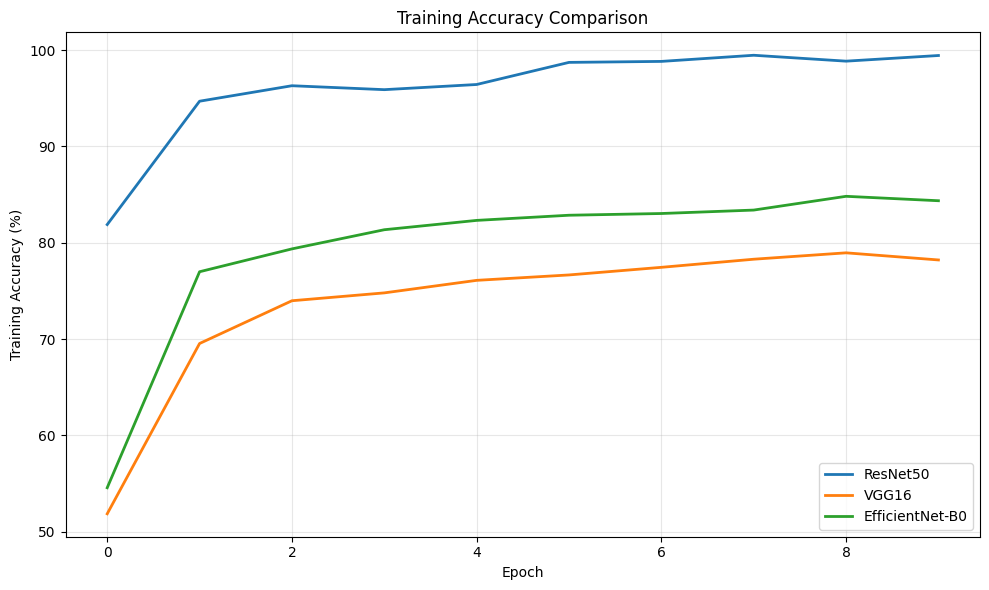

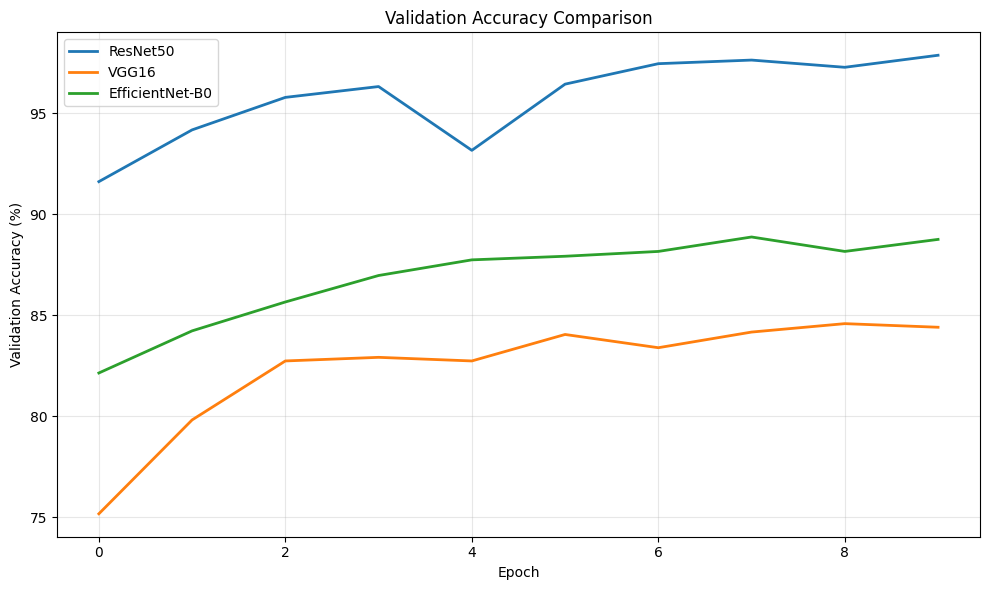

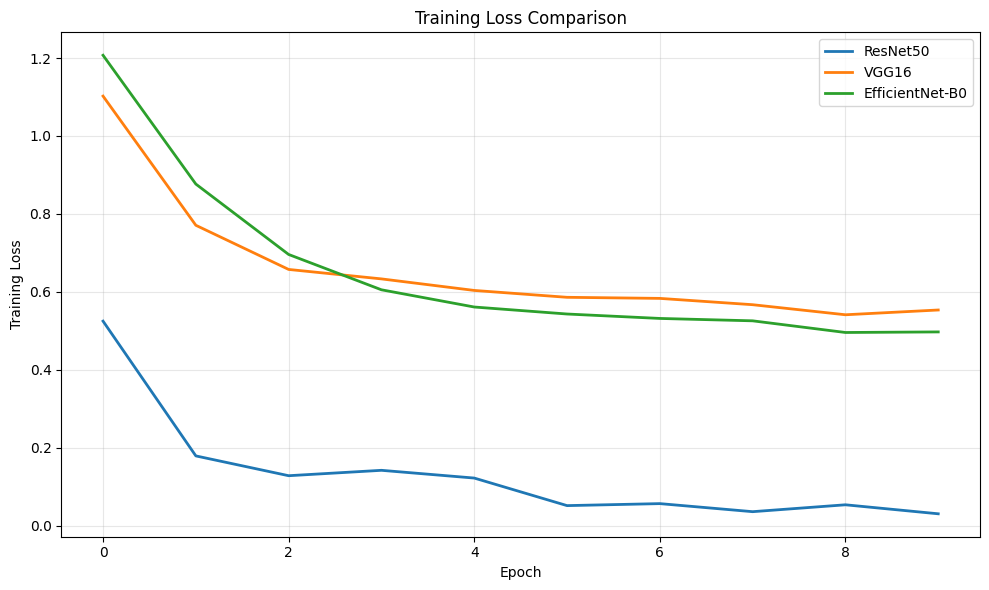

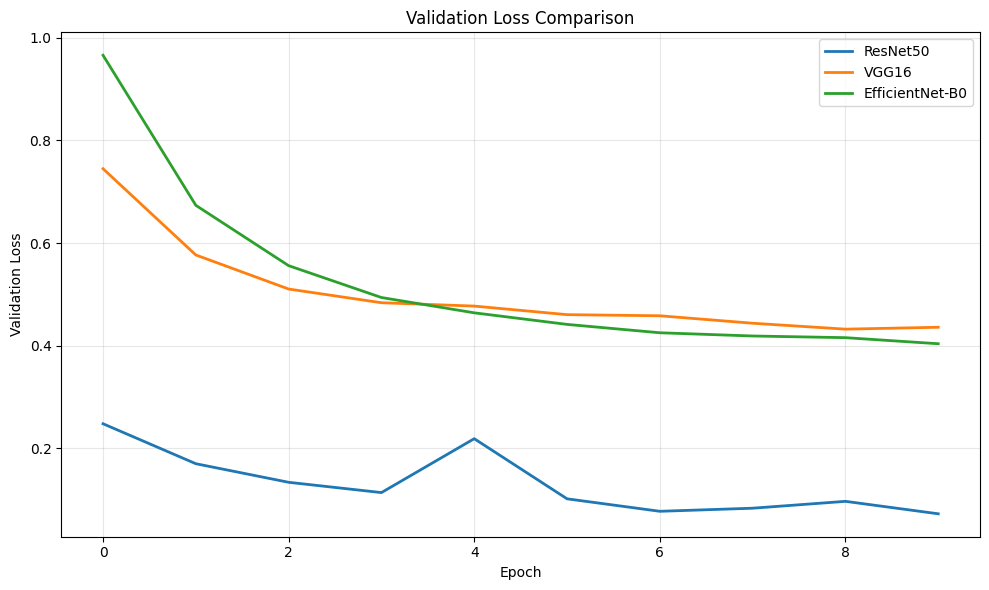

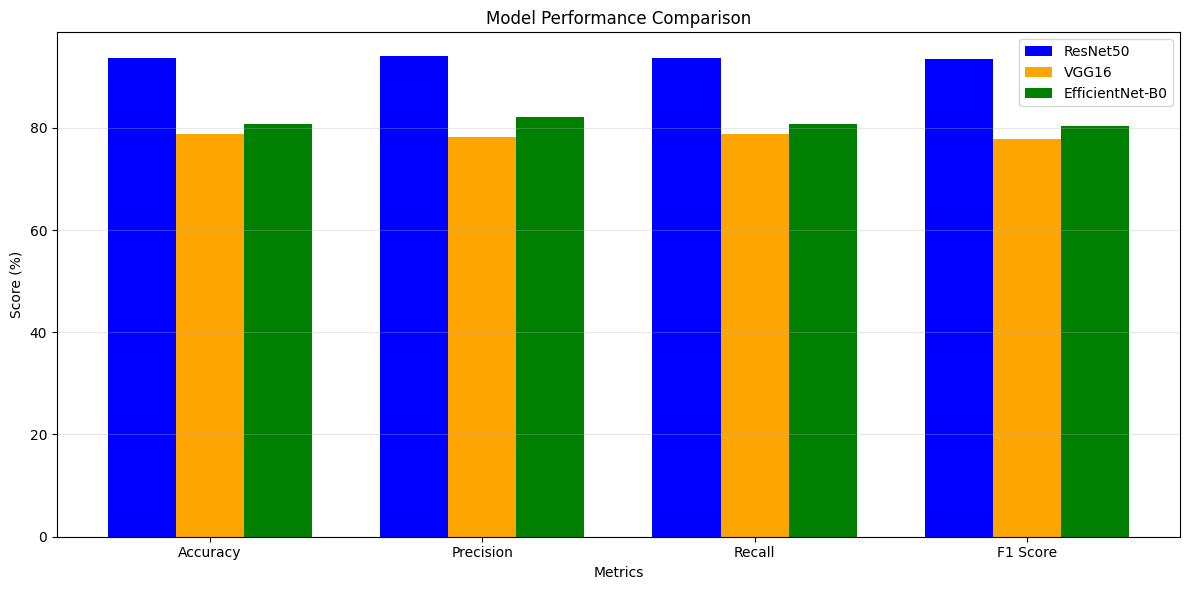

In [29]:
# 三模型对比
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report


# 图1：训练准确率曲线对比

plt.figure(figsize=(10, 6))
plt.plot(history['train_acc'], label='ResNet50', linewidth=2)
plt.plot(vgg_history['train_acc'], label='VGG16', linewidth=2)
plt.plot(eff_history['train_acc'], label='EfficientNet-B0', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Training Accuracy (%)')
plt.title('Training Accuracy Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('1_train_accuracy.png', dpi=150)
plt.show()

# 图2：验证准确率曲线对比

plt.figure(figsize=(10, 6))
plt.plot(history['val_acc'], label='ResNet50', linewidth=2)
plt.plot(vgg_history['val_acc'], label='VGG16', linewidth=2)
plt.plot(eff_history['val_acc'], label='EfficientNet-B0', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy (%)')
plt.title('Validation Accuracy Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('2_val_accuracy.png', dpi=150)
plt.show()

# 图3：训练损失曲线对比

plt.figure(figsize=(10, 6))
plt.plot(history['train_loss'], label='ResNet50', linewidth=2)
plt.plot(vgg_history['train_loss'], label='VGG16', linewidth=2)
plt.plot(eff_history['train_loss'], label='EfficientNet-B0', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.title('Training Loss Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('3_train_loss.png', dpi=150)
plt.show()

# 图4：验证损失曲线对比

plt.figure(figsize=(10, 6))
plt.plot(history['val_loss'], label='ResNet50', linewidth=2)
plt.plot(vgg_history['val_loss'], label='VGG16', linewidth=2)
plt.plot(eff_history['val_loss'], label='EfficientNet-B0', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.title('Validation Loss Comparison')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('4_val_loss.png', dpi=150)
plt.show()

# 图5：综合指标对比柱状图

def get_metrics(model, test_loader, device):
    model.eval()
    all_preds = []
    all_labels = []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    
    from sklearn.metrics import classification_report
    report = classification_report(all_labels, all_preds, target_names=categories, output_dict=True)
    accuracy = np.mean(np.array(all_preds) == np.array(all_labels)) * 100
    precision = report['weighted avg']['precision'] * 100
    recall = report['weighted avg']['recall'] * 100
    f1 = report['weighted avg']['f1-score'] * 100
    return accuracy, precision, recall, f1

# 获取三个模型的指标
resnet_metrics = get_metrics(model, test_loader, device)
vgg_metrics = get_metrics(vgg_model, test_loader, device)
eff_metrics = get_metrics(eff_model, test_loader, device)

models = ['ResNet50', 'VGG16', 'EfficientNet-B0']
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

resnet_data = [resnet_metrics[0], resnet_metrics[1], resnet_metrics[2], resnet_metrics[3]]
vgg_data = [vgg_metrics[0], vgg_metrics[1], vgg_metrics[2], vgg_metrics[3]]
eff_data = [eff_metrics[0], eff_metrics[1], eff_metrics[2], eff_metrics[3]]

x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(12, 6))
plt.bar(x - width, resnet_data, width, label='ResNet50', color='blue')
plt.bar(x, vgg_data, width, label='VGG16', color='orange')
plt.bar(x + width, eff_data, width, label='EfficientNet-B0', color='green')

plt.xlabel('Metrics')
plt.ylabel('Score (%)')
plt.title('Model Performance Comparison')
plt.xticks(x, metrics)
plt.legend()
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('5_metrics_comparison.png', dpi=150)
plt.show()